![vki_logo](https://www.skywin.be/sites/default/files/logo-membres/vki_logo_blue_rectangular.jpg)
### MODULO: A package for Multiscale Proper Orthogonal Decomposition
#### Tutorial 6: A Fast Spectral Formulation of the Multiscale Proper Orthogonal Decomposition

This tutorial illustrates the fast spectral formulation of the Multiscale Proper Orthogonal Decomposition (mPOD), recently introduced by [Belda et al, 2026](https://arxiv.org/abs/2604.12077). This sixth tutorial illustrates how to compute the fast multiscale POD of a simple dataset. The dataset is artificially generated and contains 3 modes with different temporal structures (two oscillatory modes with different frequencies and slopes, and one mode containing a single wavelet). The dataset is designed to be simple enough to allow for a clear comparison of the results of the fast mPOD with the classical FIR-based mPOD. The fast mPOD is called in two ways: once with the tapering and once without (i.e. rectangular spectral mask). The results are compared in terms of singular values and temporal modes.



## 1. Build a controlled multiscale dataset

The test matrix is assembled from three orthonormal spatial structures and three prescribed temporal signatures. This keeps the ground truth simple: two intermittent oscillatory components and one localized wavelet-like component. The amplitudes are intentionally separated so the ranking of the dominant structures is easy to inspect after decomposition.


In [9]:

import numpy as np
from modulo_vki import ModuloVKI
import os
from math import pi
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


##### PLOT CUSTOMIZATION #####
plt.rc('text', usetex=True)
plt.rc('font', family='serif')
plt.rc('xtick',labelsize=12)
plt.rc('ytick',labelsize=12)
size1 = (8, 2.5)     # figure size for overall evolution
size2 = (3, 2.5)       # figure size for details
resolution = 600    # figure resolution in DPI

target_dir = "./ex6_results"
if not os.path.exists(target_dir):
    os.makedirs(target_dir)

fig_target = target_dir + "/tempEvolFigs"
if not os.path.exists(fig_target):
    os.makedirs(fig_target)

# Create artificial spatial structure
toposes = np.zeros((3000,3))
toposes[:1000,0] = 1
toposes[1000:2000,1] = 1
toposes[2000:,2] = 1
toposes = toposes/np.linalg.norm(toposes,axis=0)

# Associate importance with the test modes
sigmas = np.diag([6000,4000,2000])

# Create artificial temporal structure
nt = 6000   # number of time steps
chronoses = np.zeros((nt,3))
for i in range(2000):
    chronoses[i,0] = np.sin(2*pi*i/60)+(i-500)/1200     # f1/fs = 1/60 + slope
for i in range(4000,6000):
    chronoses[i,1] = np.sin(2*pi*(i-4000)/30)-(i-4000)/800   # f2/fs = 1/30 + slope

# single wavelet
for i in range(2200,3000):
    chronoses[i,2] = 1
for i in range(3000,3800):
    chronoses[i,2] = -1    

for i in range(3):
    chronoses[:,i] = chronoses[:,i]/np.linalg.norm(chronoses[:,i])


## 2. Configure the spectral split

The fast mPOD call uses the frequency boundaries in `F_V` to split the temporal spectrum into bands. We compute two fast variants: one with a tapered spectral mask and one with a rectangular mask. The classical FIR-based mPOD is kept as a reference.

Set `useFortran=False` if the optional Fortran extension is not compiled in your environment.


In [10]:

# Assemble the data matrix
D = toposes @ sigmas @ chronoses.T

# Save temporal evolutions
chronTot = np.zeros((chronoses.shape[0],chronoses.shape[1]+1))
chronTot[:,0] = np.arange(nt)
chronTot[:,1:] = chronoses
np.save(f"{target_dir}/chronoses.npy", chronTot)

# Frequency split and selection of scales
useFortran = True  # Whether to use Fortran support for correlation matrix assembly in fast mPOD.
nModes = 10     # Number of modes to compute
F_V = [1/120,3/120,5/120,10/120]   # Frequency splitting vector in Hz, assuming fs = 1 (normalized frequencies) for this tutorial
Keep = [1, 1, 1, 1, 0]  # Which scales to keep (0 means not processed, 1 means processed)
winType = "hann" # Type of window for the tapering (hann, hamming, blackman, etc)
taper = [1/300, 1/300, 1/300, 1/300, 1/300] # Taper width in Hz for each scale, assuming fs = 1 (normalized frequencies) for this tutorial
mode = "fullK" # Type of computation (supports "fullK", "bandK", "fullSVD", "randSVD")


# MODULO object initialization
if useFortran:
    m = ModuloVKI(data=np.nan_to_num(D), n_Modes = nModes, dtype=np.float64)  # dtype = np.float64 required for fortran support
else:
    m = ModuloVKI(data=np.nan_to_num(D), n_Modes = nModes)


MODULO (MODal mULtiscale pOd) is a software developed at the von Karman Institute to perform data driven modal decomposition of numerical and experimental data. 

Modulo assumes you have a uniform grid. If not, please give the weights as parameters of MODULO!


## 3. Compute fast mPOD and the FIR reference

The first call computes the tapered fast mPOD. The second call removes tapering to show the effect of a rectangular spectral mask. The final call runs the original FIR-filtered mPOD so the singular values and temporal modes can be compared directly.


In [11]:
# Fast mPOD call
phi, psi, sig = m.fastmPOD(F_V, 1, Keep, winType = winType, taper = taper, mode = mode, GThresh=5, ncpus=9, useFortran=useFortran) 
np.save(f"{target_dir}/phi.npy", phi)
np.save(f"{target_dir}/psi.npy", psi)
np.save(f"{target_dir}/sig.npy", sig)

# Rectangular mask
phiNT, psiNT, sigNT = m.fastmPOD(F_V, 1, Keep, winType = winType, taper = None, mode = mode, GThresh=5, ncpus=9, useFortran=useFortran)
np.save(f"{target_dir}/phiNT.npy", phiNT)
np.save(f"{target_dir}/psiNT.npy", psiNT)
np.save(f"{target_dir}/sigNT.npy", sigNT)

# Parameters for FIR approach (classic mPOD approach)
Nf = [1001, 1001, 1001, 1001, 1001]    # FIR orders for all scales
Nf = np.array(Nf)
Ex = np.max(Nf)+2  # This must be at least as Nf.
dt = 1; boundaries = 'wrap'; MODE = 'reduced'

Phi_M, Psi_M, Sigmas_M = m.mPOD(Nf, Ex, F_V, Keep, nModes ,boundaries, MODE, dt, False)
np.save(f"{target_dir}/phiFIR.npy", Phi_M)
np.save(f"{target_dir}/Psi_M.npy", Psi_M)
np.save(f"{target_dir}/sigFIR.npy", Sigmas_M)

Computing mPOD using fast mPOD algorithm ...
Transforming data to spectral domain ...
Precomputing scale energies for 4 kept scales ...
Keeping scales  [1 2 3 4]
Looping through scales in decreasing energy order ... 

Processing band 1/5 (0.0 Hz - 0.0 Hz), 58.2 % of resolved energy in 99 bins ...
 -> Computing smoothing mask of width 20 bins
 -> Using precomputed K_F
 -> Applying smoothing to K_Fsc
 -> Computing eigenvalues
 -> Selecting significant modes
 -> Selection unapplicable, taking 10 modes 

Processing band 2/5 (0.0 Hz - 0.0 Hz), 35.8 % of resolved energy in 202 bins ...
 -> Computing smoothing mask of width 20 bins
 -> Using precomputed K_F
 -> Applying smoothing to K_Fsc
 -> Computing eigenvalues
 -> Selecting significant modes
 -> Kept 10 modes 

Processing band 3/5 (0.0 Hz - 0.0 Hz), 5.7 % of resolved energy in 198 bins ...
 -> Computing smoothing mask of width 20 bins
 -> Using precomputed K_F
 -> Applying smoothing to K_Fsc
 -> Computing eigenvalues
 -> Selecting signifi

## 4. Check amplitudes and the prescribed temporal content

The singular values quantify how closely the fast spectral formulation reproduces the FIR reference. The plot below shows the three temporal signatures used to generate the synthetic dataset, before the modal estimates are inspected mode by mode.



--------------------------
RESULTS:

Singular values fast mPOD:
[4456.24231515 3977.44967097 3574.14284794 1972.65373724 1752.39841392
  311.3700354   249.68180901  242.29556209  222.24342851  165.97736654]

Singular values rectangular mask fast mPOD:
[4461.44915672 3982.00151249 3576.99314504 1977.36759871 1753.94131071
  341.92201214  273.85303716  258.92334984  243.74276454  175.28992237]

Singular values classical (FIR-based) mPOD:
[4465.69530165 3977.66803662 3577.55940236 1978.01751874 1755.1186242
  339.06868864  260.2159156   256.9106084   239.92034454  172.06078005]

Singular values difference (absolute) fast vs FIR:
[ -9.4529865   -0.21836564  -3.41655442  -5.3637815   -2.72021028
 -27.69865324 -10.53410659 -14.61504632 -17.67691602  -6.08341351]

Singular values difference (relative) fast vs FIR:
[-2.11680060e-03 -5.48979053e-05 -9.54995861e-04 -2.71169565e-03
 -1.54987261e-03 -8.16903895e-02 -4.04821764e-02 -5.68876716e-02
 -7.36782704e-02 -3.53561893e-02]

Singular values

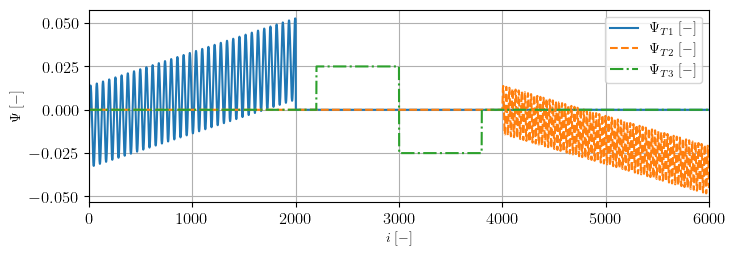

In [12]:

# Compare singular values
sigDiff = sig - Sigmas_M
sigDiffNT = sigNT - Sigmas_M
print("\n--------------------------")
print("RESULTS:")
print("\nSingular values fast mPOD:")
print(sig)
print("\nSingular values rectangular mask fast mPOD:")
print(sigNT)
print("\nSingular values classical (FIR-based) mPOD:")
print(Sigmas_M)


print("\nSingular values difference (absolute) fast vs FIR:")
print(sigDiff)
print("\nSingular values difference (relative) fast vs FIR:")
print(sigDiff/Sigmas_M)


print("\nSingular values difference (absolute) rectangular mask vs FIR:")
print(sigDiffNT)
print("\nSingular values difference (relative) rectangular mask vs FIR:")
print(sigDiffNT/Sigmas_M)


plt.figure(figsize=size1)
plt.plot(np.arange(nt),chronoses[:,0],label=r"$\Psi_{T1} \; [-]$")
plt.plot(np.arange(nt),chronoses[:,1],linestyle='--',label=r"$\Psi_{T2} \; [-]$")
plt.plot(np.arange(nt),chronoses[:,2],linestyle='-.',label=r"$\Psi_{T3} \; [-]$")
ax = plt.gca()
ax.set_aspect('auto', adjustable='box')
ax.grid(which = 'both')
#plt.title("Time evolution mode %d"%(i+1))
plt.xlabel(r"$i \; [-]$")
plt.ylabel(r'$\Psi \; [-]$')
plt.xlim([0,nt])
plt.legend()
plt.show()


## 5. Export detailed temporal-mode comparisons

For each computed mode, the notebook aligns the sign of the fast estimates with the FIR reference, then writes one full-history PDF and five detail-window PDFs. The final detail window (`ModeXDet5.pdf`) highlights the last active interval of the synthetic signal.


In [13]:
for i in range(nModes):
    # Plot time evolution of mode

    minus = np.linalg.norm(psi[:,i]-Psi_M[:,i])
    plus = np.linalg.norm(psi[:,i]+Psi_M[:,i])

    if plus < minus:
        psi[:,i] = -1*psi[:,i]

    minus = np.linalg.norm(psiNT[:,i]-Psi_M[:,i])
    plus = np.linalg.norm(psiNT[:,i]+Psi_M[:,i])

    if plus < minus:
        psiNT[:,i] = -1*psiNT[:,i]
        
    plt.figure(figsize=size1)
    plt.plot(np.arange(nt),Psi_M[:,i],label="FIR-based mPOD")
    plt.plot(np.arange(nt),psi[:,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(nt),psiNT[:,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    plt.xlim([0,nt])
    plt.legend()
    plt.savefig(fig_target + "/Mode%d.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()
    

    # Details around jumps
    plt.figure(figsize=size2)
    plt.plot(np.arange(500),Psi_M[:500,i],label="FIR-based mPOD")
    plt.plot(np.arange(500),psi[:500,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(500),psiNT[:500,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    #plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    plt.xlim([0,499])
    #plt.legend(loc='lower right')
    plt.savefig(fig_target + "/Mode%dDet1.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()

    # Details around jumps
    plt.figure(figsize=size2)
    plt.plot(np.arange(1500,2500),Psi_M[1500:2500,i],label="FIR-based mPOD")
    plt.plot(np.arange(1500,2500),psi[1500:2500,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(1500,2500),psiNT[1500:2500,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    #plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    plt.xlim([1500,2500])
    #plt.legend()
    plt.savefig(fig_target + "/Mode%dDet2.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()

    # Details around jumps
    plt.figure(figsize=size2)
    plt.plot(np.arange(2750,3250),Psi_M[2750:3250,i],label="FIR-based mPOD")
    plt.plot(np.arange(2750,3250),psi[2750:3250,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(2750,3250),psiNT[2750:3250,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    #plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    plt.xlim([2750,3250])
    #plt.legend()
    plt.savefig(fig_target + "/Mode%dDet3.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()

    # Details around jumps
    plt.figure(figsize=size2)
    plt.plot(np.arange(3500,4500),Psi_M[3500:4500,i],label="FIR-based mPOD")
    plt.plot(np.arange(3500,4500),psi[3500:4500,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(3500,4500),psiNT[3500:4500,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    #plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    #plt.legend()
    plt.xlim([3500,4500])
    plt.savefig(fig_target + "/Mode%dDet4.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()

    # Details around jumps
    plt.figure(figsize=size2)
    plt.plot(np.arange(5500,6000),Psi_M[5500:,i],label="FIR-based mPOD")
    plt.plot(np.arange(5500,6000),psi[5500:,i],linestyle='--',label="fast mPOD")
    plt.plot(np.arange(5500,6000),psiNT[5500:,i],linestyle='-.',label="rectangular spectral mask")
    ax = plt.gca()
    ax.set_aspect('auto', adjustable='box')
    ax.grid(which = 'both')
    #plt.title("Time evolution mode %d"%(i+1))
    plt.xlabel(r"$i \; [-]$")
    #plt.ylabel(r'$\Psi_{%d} \; [-]$'%(i+1))
    #plt.legend()
    plt.xlim([5500,5999])
    plt.savefig(fig_target + "/Mode%dDet5.pdf"%(i+1), dpi=resolution, bbox_inches="tight")
    plt.close()

## 6. First five recovered temporal modes

The summary below reproduces the decomposition of the artificial dataset to showcase the Gibbs phenomenon (Fig. 4 in the referenced paper).


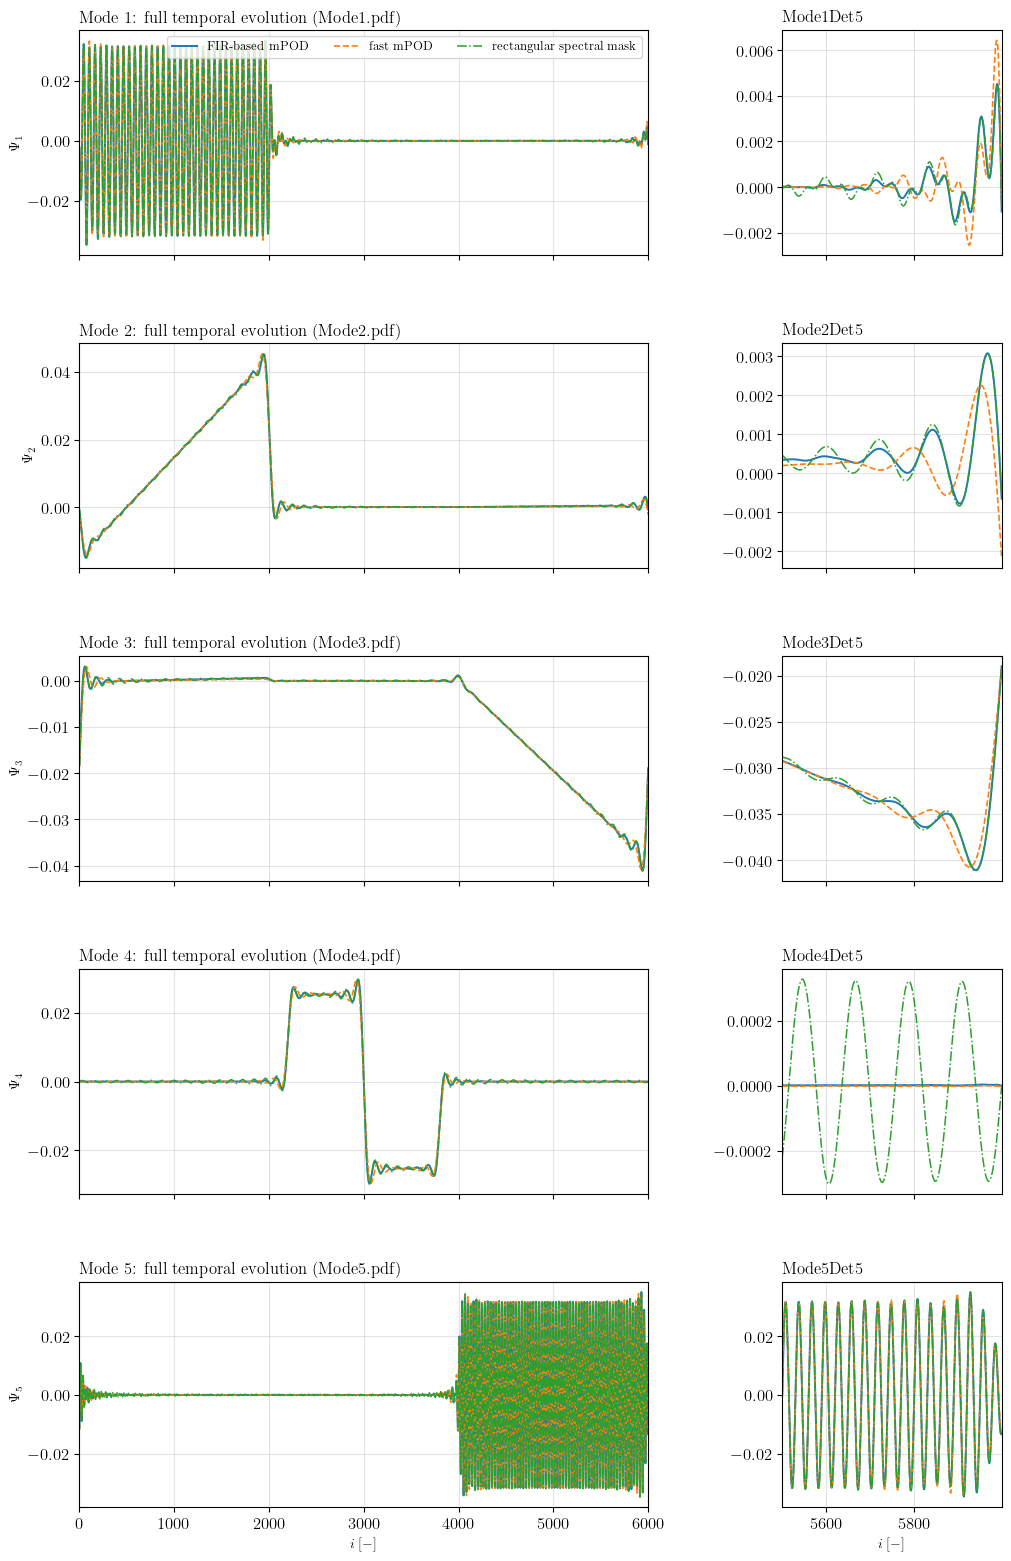

In [16]:
# GridSpec summary: first five modes, with full evolution and Det5 zoom
modes_to_show = min(5, nModes)
full_span = np.arange(nt)
detail_slice = slice(5500, nt)
detail_span = np.arange(5500, nt)

fig = plt.figure(figsize=(10, 3.1 * modes_to_show), constrained_layout=True)
gs = GridSpec(modes_to_show, 2, figure=fig, width_ratios=[3.5, 1.35], hspace=0.2, wspace=0.1)

for row in range(modes_to_show):
    mode_id = row + 1
    ax_full = fig.add_subplot(gs[row, 0])
    ax_det = fig.add_subplot(gs[row, 1])

    ax_full.plot(full_span, Psi_M[:, row], label="FIR-based mPOD", linewidth=1.4)
    ax_full.plot(full_span, psi[:, row], linestyle="--", label="fast mPOD", linewidth=1.2)
    ax_full.plot(full_span, psiNT[:, row], linestyle="-.", label="rectangular spectral mask", linewidth=1.1)
    ax_full.set_xlim(0, nt)
    ax_full.set_ylabel(r"$\Psi_%d$" % mode_id)
    ax_full.grid(which="both", alpha=0.35)
    ax_full.set_title(f"Mode {mode_id}: full temporal evolution (Mode{mode_id}.pdf)", loc="left")

    ax_det.plot(detail_span, Psi_M[detail_slice, row], linewidth=1.4)
    ax_det.plot(detail_span, psi[detail_slice, row], linestyle="--", linewidth=1.2)
    ax_det.plot(detail_span, psiNT[detail_slice, row], linestyle="-.", linewidth=1.1)
    ax_det.set_xlim(5500, nt - 1)
    ax_det.grid(which="both", alpha=0.35)
    ax_det.set_title(f"Mode{mode_id}Det5", loc="left")

    if row == 0:
        ax_full.legend(loc="upper right", ncol=3, fontsize=9)
    if row < modes_to_show - 1:
        ax_full.set_xticklabels([])
        ax_det.set_xticklabels([])
    else:
        ax_full.set_xlabel(r"$i \; [-]$")
        ax_det.set_xlabel(r"$i \; [-]$")

fig.savefig(f"{fig_target}/First5Modes_GridSpec.pdf", dpi=resolution, bbox_inches="tight")
plt.show()
